In [14]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.feature_extraction.text import CountVectorizer

In [2]:
df=pd.read_csv("spam.csv")

In [3]:
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [31]:
X=df.drop(columns=["Unnamed: 2","Unnamed: 3","Unnamed: 4"])
y=df['v1']
X=df["v2"]

<Axes: xlabel='count', ylabel='v1'>

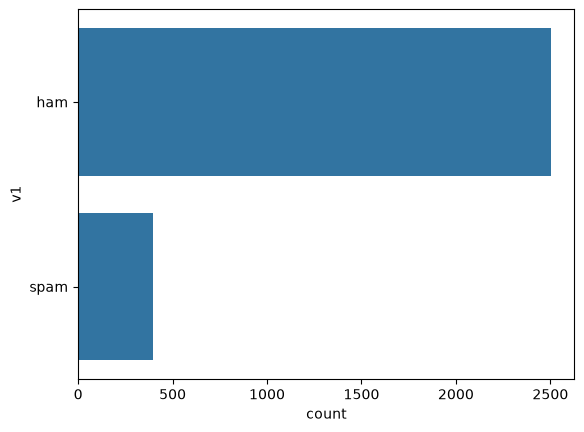

In [27]:
sns.countplot(
    df['v1']
)

<Axes: xlabel='v1', ylabel='Count'>

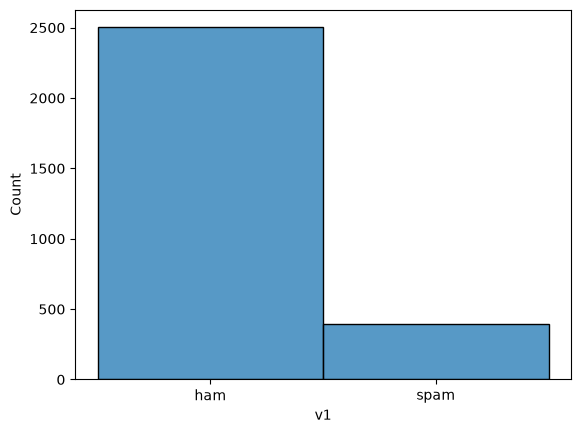

In [52]:
sns.histplot(df["v1"])

In [28]:
y

0        ham
1        ham
2       spam
3        ham
4        ham
        ... 
2893     ham
2894     ham
2895    spam
2896     ham
2897     ham
Name: v1, Length: 2898, dtype: str

In [16]:
df.isnull().sum()

v1               0
v2               0
Unnamed: 2    2874
Unnamed: 3    2892
Unnamed: 4    2895
dtype: int64

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size=0.2,
    random_state=42,
)

In [37]:
X_train

2136                          Well done and ! luv ya all 
163     -PLS STOP bootydelious (32/F) is inviting you ...
1936        My planning usually stops at \find hella weed
252                           What you doing?how are you?
1860    It could work, we'll reach a consensus at the ...
                              ...                        
1638                Great comedy..cant stop laughing da:)
1095                              Ryder unsold.now gibbs.
1130                            Howz pain?hope u r fine..
1294     Aiyah u did ok already lar. E nydc at wheellock?
860                   In work now. Going have in few min.
Name: v2, Length: 2318, dtype: str

In [38]:
y_train

2136     ham
163     spam
1936     ham
252      ham
1860     ham
        ... 
1638     ham
1095     ham
1130     ham
1294     ham
860      ham
Name: v1, Length: 2318, dtype: str

In [39]:
ve = CountVectorizer()
X_train = ve.fit_transform(X_train)
X_test = ve.transform(X_test)

In [40]:
X_test

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 6814 stored elements and shape (580, 5475)>

In [41]:
model = MultinomialNB()
model.fit(X_train, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[2006., 312.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.14,-2.01]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U4](2,)","['ham','spam']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 5475)","[[ 0., 0., 1.,..., 1., 0., 1.], [ 7.,15., 0.,..., 0., 1., 0.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 5475)","[[-10.38,-10.38, -9.69,..., -9.69,-10.38, -9.69], [ -7.38, -6.69, -9.46,..., -9.46, -8.77, -9.46]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5475


In [42]:
pred = model.predict(X_test)

In [43]:
print(pred)

['ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham'
 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham'
 'spam' 'ham' 'ham' 'ham' 'ham' 'ham' 'spam' 'ham' 'ham' 'ham' 'ham' 'ham'
 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'spam' 'ham'
 'ham' 'ham' 'ham' 'ham' 'spam' 'ham' 'ham' 'ham' 'spam' 'ham' 'ham' 'ham'
 'spam' 'spam' 'ham' 'ham' 'ham' 'ham' 'spam' 'ham' 'ham' 'ham' 'ham'
 'ham' 'ham' 'spam' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham'
 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham'
 'ham' 'ham' 'spam' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham'
 'ham' 'ham' 'ham' 'ham' 'ham' 'spam' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham'
 'ham' 'ham' 'ham' 'ham' 'spam' 'ham' 'ham' 'ham' 'spam' 'ham' 'ham' 'ham'
 'spam' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham'
 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'spam' 'ham' 'spam' 'ham' 'ham'
 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham

In [44]:
print("accuracy_score: ", accuracy_score(y_test, pred))

accuracy_score:  0.9844827586206897


In [45]:
print("Training",model.score(X_train, y_train))
model.score(X_test, y_test)

Training 0.9952545297670405


0.9844827586206897

In [46]:
new = [
    "Your subscription has been renewed successfully. No further action is required."
]

new_ve = ve.transform(new)
y_pred = model.predict(new_ve)
print("prediction: ", y_pred)

prediction:  ['spam']
